# Deep learning: a sequence model that judges the whole rep

The rule engine checks a few hand-picked numbers (depth at the bottom, biggest drop on the way up...).
Here a **neural network reads the entire rep frame by frame** and learns the fault patterns itself.

| | GA NN-Classification notebook | This notebook |
|---|---|---|
| Input | one image, flattened | one rep: **96 frames × 10 signals** (a time series) |
| Layers | `Dense` | `Conv1D` (short shapes: a bounce, a dip, a step) → `GRU` (their order in time) → `Dense` |
| Output | `softmax`, one class | **5 × `sigmoid`**: one probability per fault (multi-label: a rep can be high *and* bounce) |
| Loss | categorical cross-entropy | binary cross-entropy |

**Faults:** `depth` (not deep enough) · `lockout` (knees not locked) · `bounce` (double bounce) ·
`downward` (downward movement on the way up) · `feet` (step).

**Plan (sim-to-real):** pre-train on synthetic reps where labels are free, then fine-tune on your real
labelled reps (section 6). Keras 3 runs on TensorFlow (GA setup), PyTorch or JAX.

In [1]:
import sys
from pathlib import Path
# make `liftjudge` importable without installing (pip install -e . also works)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import keras
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score
from liftjudge.dl import (FAULTS, CHANNELS, synthetic_training_set, build_model, fine_tune, predict_faults)
keras.utils.set_random_seed(0)
print("Keras", keras.__version__, "backend:", keras.backend.backend())

Keras 3.15.1 backend: torch


## 1. Data: 2,000 labelled reps from 60 simulated lifters
Each lifter has their own tempo, keypoint noise, filmed side and frame rate; some frames are dropped as if
the detector missed the lifter. The hidden referee depth line is at a thigh angle of 3° below parallel.

In [2]:
X, Y, meta = synthetic_training_set(n_reps=2000, n_lifters=60, seed=0)
print("X:", X.shape, "(reps, frames, signals)   Y:", Y.shape)
print("signals:", CHANNELS)
rates = pd.Series(Y.mean(0), index=FAULTS).round(2)
print("\nfault rate per label:\n", rates.to_string())
print("\ngood lifts (no fault):", round((Y.sum(1) == 0).mean(), 2))

X: (2000, 96, 10) (reps, frames, signals)   Y: (2000, 5)
signals: ('depth', 'hip_height', 'hip_vel', 'knee_angle', 'hip_angle', 'ankle_dx', 'ankle_dy', 'shoulder_dx', 'leg_conf', 'duration')

fault rate per label:
 depth       0.49
lockout     0.18
bounce      0.18
downward    0.18
feet        0.18

good lifts (no fault): 0.23


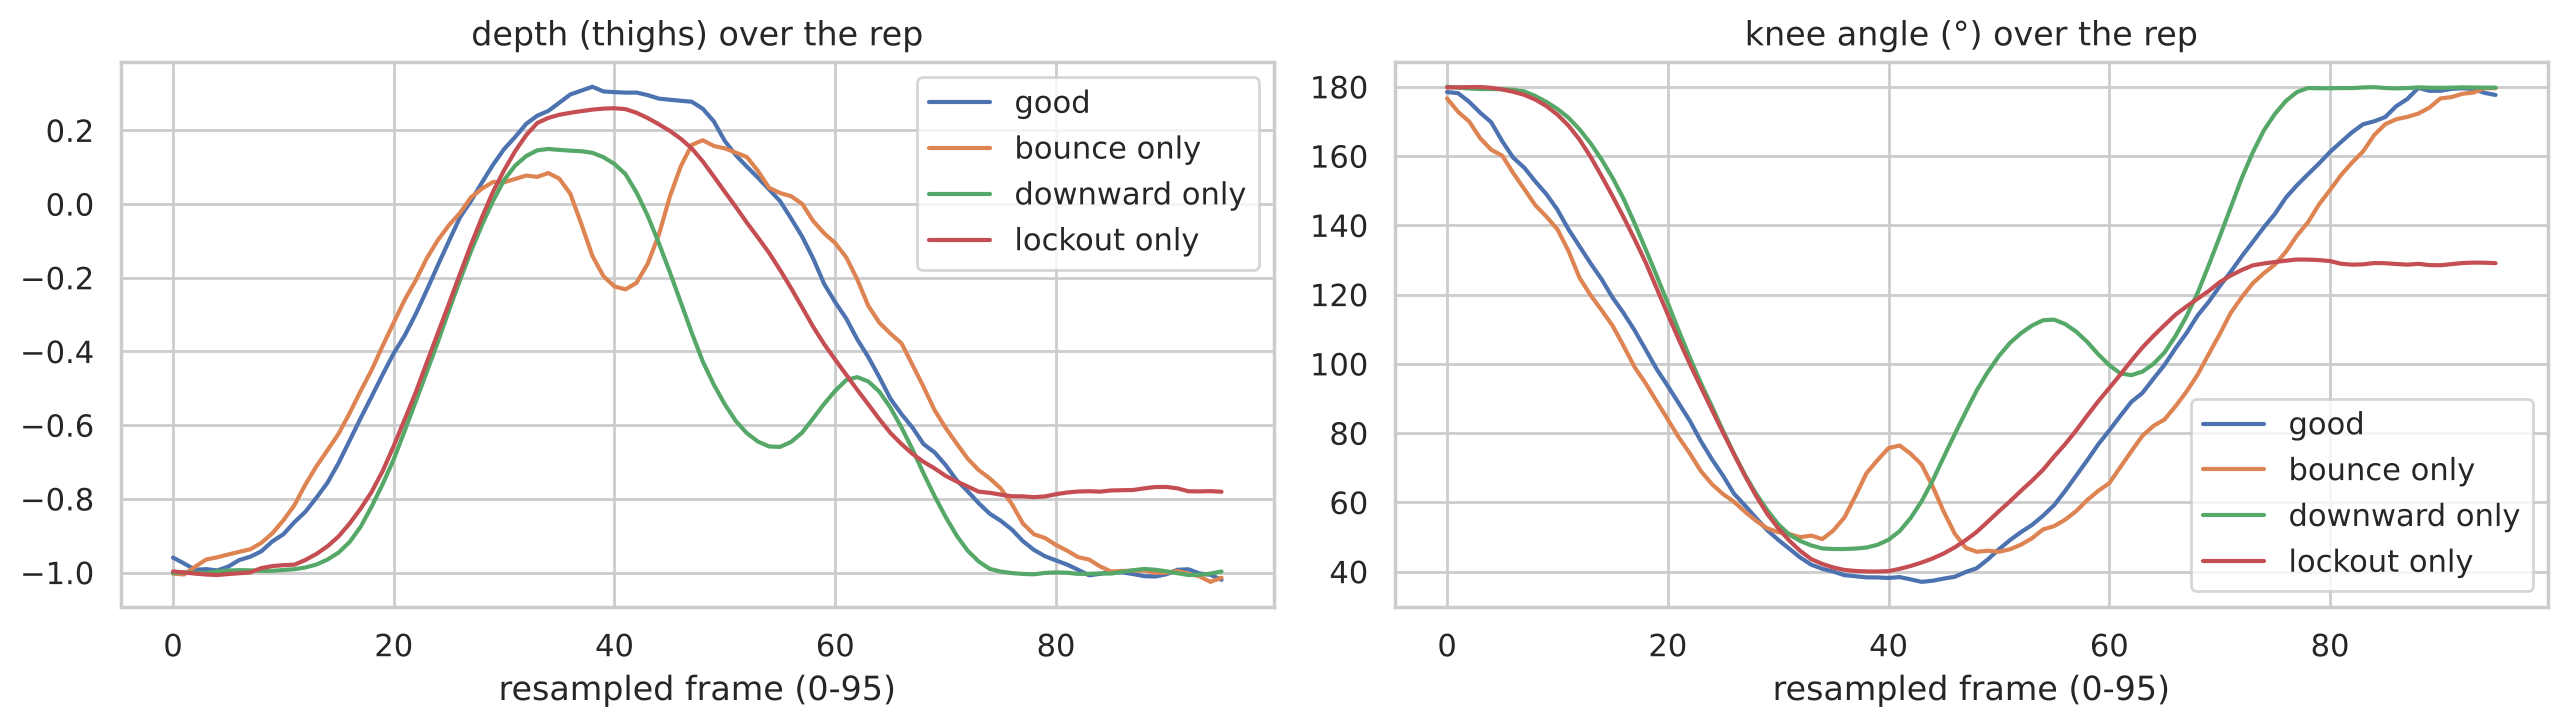

In [3]:
# what the network sees: the depth channel for one rep of each kind
examples = {"good": (Y.sum(1) == 0), "bounce only": (Y[:, 2] == 1) & (Y.sum(1) == 1),
            "downward only": (Y[:, 3] == 1) & (Y.sum(1) == 1), "lockout only": (Y[:, 1] == 1) & (Y.sum(1) == 1)}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, mask in examples.items():
    i = np.flatnonzero(mask)[0]
    ax[0].plot(X[i, :, 0], label=name)
    ax[1].plot(X[i, :, 3] * 180, label=name)
ax[0].set_title("depth (thighs) over the rep"); ax[1].set_title("knee angle (°) over the rep")
for a in ax: a.set_xlabel("resampled frame (0-95)"); a.legend()
plt.tight_layout()

## 2. Split by lifter
Train, validation and test contain **different lifters**, so the score shows how the model does on people it
has never seen, not on reps from people it memorised.

In [4]:
g = meta.lifter.to_numpy()
trv, te = next(GroupShuffleSplit(test_size=0.2, random_state=1).split(X, Y, g))
tr_i, va_i = next(GroupShuffleSplit(test_size=0.2, random_state=2).split(X[trv], Y[trv], g[trv]))
tr, va = trv[tr_i], trv[va_i]
print(f"train {len(tr)} reps / {len(set(g[tr]))} lifters | val {len(va)} / {len(set(g[va]))} | test {len(te)} / {len(set(g[te]))}")
assert not set(g[tr]) & set(g[te])

train 1238 reps / 38 lifters | val 361 / 10 | test 401 / 12


## 3. Model

In [5]:
model = build_model(X[tr])   # the Normalization layer learns the mean/std of the training reps
model.summary()

Model: "rep_fault_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rep_signals (InputLayer)        │ (None, 96, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize (Normalization)       │ (None, 96, 10)         │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 96, 32)         │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 96, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 96, 48)         │         7,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling1D)             │ (None, 48, 48)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (Bidirectional)             │ (None, 64)             │        15,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ faults (Dense)                  │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,498 (107.41 KB)

 Trainable params: 27,413 (107.08 KB)

 Non-trainable params: 85 (340.00 B)

## 4. Train with early stopping

stopped after 39 epochs; best val_loss 0.012 at epoch 29


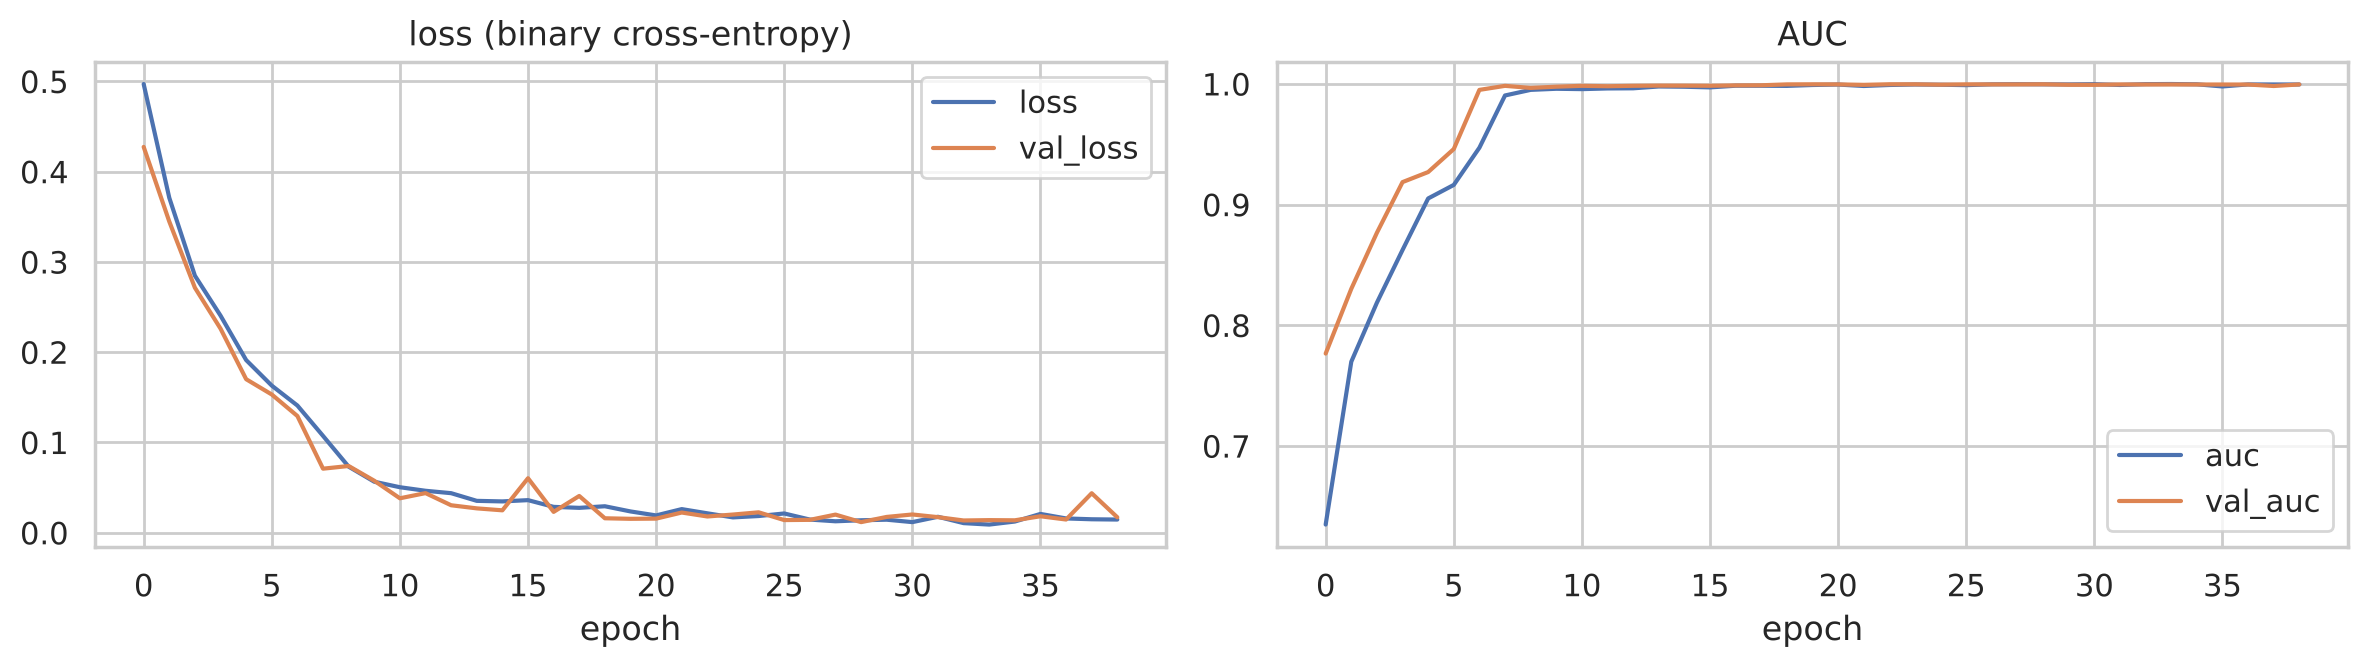

In [6]:
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist = model.fit(X[tr], Y[tr], validation_data=(X[va], Y[va]), epochs=120, batch_size=32,
                 callbacks=[stop], verbose=0)
h = pd.DataFrame(hist.history)
print(f"stopped after {len(h)} epochs; best val_loss {h.val_loss.min():.3f} at epoch {h.val_loss.idxmin() + 1}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="loss (binary cross-entropy)")
h[["auc", "val_auc"]].plot(ax=ax[1], title="AUC")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout()

## 5. Evaluate on unseen lifters, and compare with the rule engine
The rule engine counts a **borderline** depth as "not a good lift" here, because it refuses to approve it.

In [7]:
P = model.predict(X[te], verbose=0)
pred = (P >= 0.5).astype(int)
rules = meta.iloc[te][[f"rule_{k}" for k in FAULTS]].to_numpy().astype(int)
rows = []
for k, f in enumerate(FAULTS):
    for name, p in (("rules", rules[:, k]), ("neural net", pred[:, k])):
        rows.append({"fault": f, "method": name,
                     "precision": precision_score(Y[te, k], p, zero_division=0),
                     "recall": recall_score(Y[te, k], p, zero_division=0),
                     "F1": f1_score(Y[te, k], p, zero_division=0)})
cmp = pd.DataFrame(rows)
cmp.pivot(index="fault", columns="method", values="F1").loc[list(FAULTS)].round(3)

method,neural net,rules
fault,,
depth,0.972,0.912
lockout,1.000,1.000
bounce,1.000,0.986
downward,0.993,0.986
feet,1.000,1.000


Text(0.5, 1.0, 'Rules vs neural network, per fault')

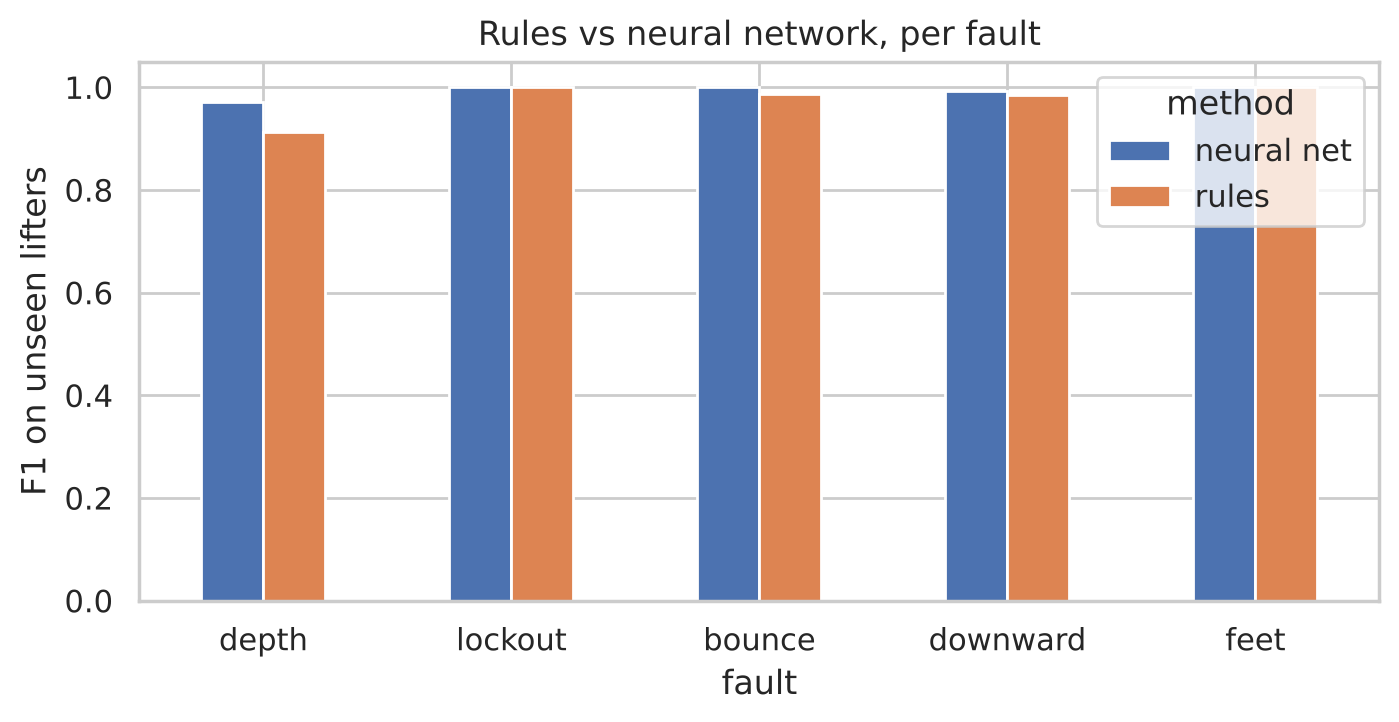

In [8]:
ax = cmp.pivot(index="fault", columns="method", values="F1").loc[list(FAULTS)].plot.bar(figsize=(8, 3.5), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 on unseen lifters"); ax.set_title("Rules vs neural network, per fault")

In [9]:
# the decision that matters: GOOD LIFT vs NO LIFT
true_nolift = (Y[te].sum(1) > 0).astype(int)
for name, p in (("rules", (rules.sum(1) > 0).astype(int)), ("neural net", (pred.sum(1) > 0).astype(int))):
    print(f"=== {name}")
    print(classification_report(true_nolift, p, target_names=["good lift", "no lift"], digits=3))

=== rules
              precision    recall  f1-score   support

   good lift      1.000     0.838     0.912        99
     no lift      0.950     1.000     0.974       302

    accuracy                          0.960       401
   macro avg      0.975     0.919     0.943       401
weighted avg      0.962     0.960     0.959       401

=== neural net
              precision    recall  f1-score   support

   good lift      0.990     0.990     0.990        99
     no lift      0.997     0.997     0.997       302

    accuracy                          0.995       401
   macro avg      0.993     0.993     0.993       401
weighted avg      0.995     0.995     0.995       401



### Where they disagree: depth near the line
Plot the predicted probability of `depth` against the true thigh angle. The network has to find the hidden
line at 3° from the labels alone; the rule engine uses the default offset and a borderline band.

Text(0.5, 1.0, 'Network depth probability vs true depth')

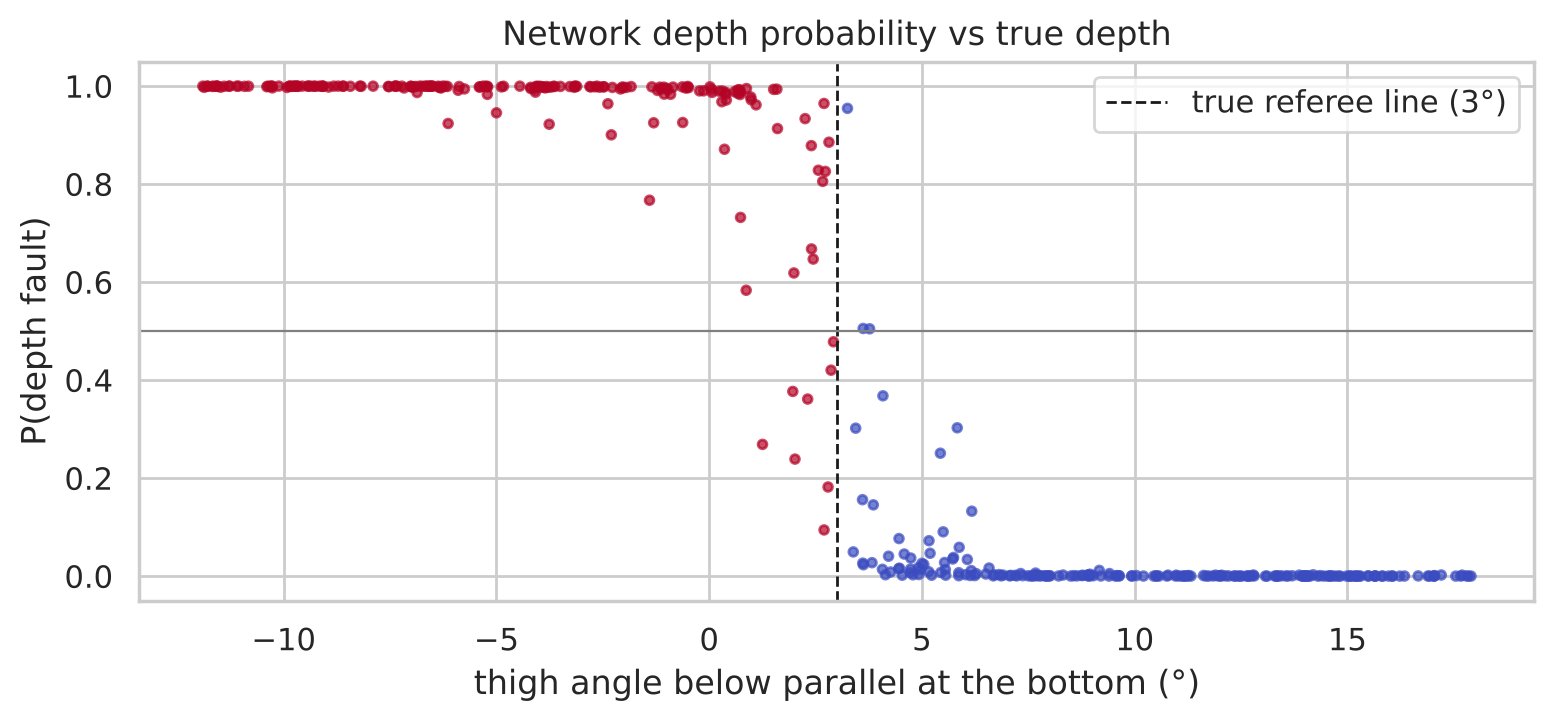

In [10]:
d = meta.iloc[te].assign(p_depth=P[:, 0], true=Y[te, 0])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.scatter(d.depth_deg, d.p_depth, s=10, c=d.true, cmap="coolwarm", alpha=0.7)
ax.axvline(3, color="k", ls="--", lw=1, label="true referee line (3°)")
ax.axhline(0.5, color="grey", lw=0.8)
ax.set_xlabel("thigh angle below parallel at the bottom (°)"); ax.set_ylabel("P(depth fault)")
ax.legend(); ax.set_title("Network depth probability vs true depth")

## 6. Save, and use it on a video

In [11]:
(ROOT / "models").mkdir(exist_ok=True)
model.save(ROOT / "models" / "rep_fault_net.keras")
print("saved models/rep_fault_net.keras")

# use it like the rule engine, on any analysed video (here: a synthetic one with a bounce)
from liftjudge import analyze_pose
from liftjudge.synthetic import make_squat
res = analyze_pose(make_squat(depth_deg=12, bounce=True, reps=1, seed=7), "squat")
print(res.summary())
predict_faults(model, res).round(3)

saved models/rep_fault_net.keras


Rep 1: NO LIFT  [blue card]
   ok Depth: hip crease below the knee (+0.18 thighs)
   ok Knees locked at the start (178°)
   ok Knees locked at the finish (180°)
   X  Double bounce: hips rose 0.36 thighs then dropped again in the hole
   ok Continuous ascent, no downward movement
   ok Feet stayed in place


,rep,depth,lockout,bounce,downward,feet,dl_label
0,1,0.0,0.001,0.999,0.0,0.0,NO LIFT


## 7. Fine-tune on your real reps (sim-to-real)
Synthetic squats are cleaner than real ones (no belt, no plates hiding the knee, perfect camera angle), so the
model must be adapted to real data. Freeze the convolution + GRU layers, retrain the head on real labelled reps
with a small learning rate, and evaluate on lifters it hasn't seen. Unfreeze more layers once there are a few
hundred real reps.

`data/labels.csv` needs one 0/1 column per fault: `depth`, `lockout`, `bounce`, `downward`, `feet`.

In [12]:
LABELS = ROOT / "data" / "labels.csv"
if LABELS.exists():
    from liftjudge.dl import analysis_sequences
    from liftjudge.keypoints import PoseSequence, extract_pose
    labels = pd.read_csv(LABELS)
    Xr, Yr = [], []
    for vid, rows in labels.groupby("video_id"):
        video = next((ROOT / "data" / "raw").rglob(f"{vid}.*"), None)
        kp = video.with_name(f"{vid}_keypoints.csv") if video else None
        if video is None:
            continue
        pose = PoseSequence.load_csv(kp) if kp.exists() else extract_pose(video)
        seqs = analysis_sequences(analyze_pose(pose, "squat"))
        for _, r in rows.iterrows():
            if r.rep <= len(seqs):
                Xr.append(seqs[r.rep - 1]); Yr.append([r[f] for f in FAULTS])
    Xr, Yr = np.stack(Xr), np.array(Yr, "float32")
    print("real reps:", Xr.shape)
    tuned = keras.saving.load_model(ROOT / "models" / "rep_fault_net.keras")
    fine_tune(tuned, Xr, Yr)
    tuned.save(ROOT / "models" / "rep_fault_net_real.keras")
else:
    print("No data/labels.csv yet: record and label some reps first (see data/README.md).")

No data/labels.csv yet: record and label some reps first (see data/README.md).


## Takeaways
- On synthetic data the network learns every fault from raw signals, including the hidden depth line, without
  being told any thresholds.
- The rule engine stays: it is **explainable** ("downward movement at frame 112") and needs no training data.
  The network is a second opinion, and where the two disagree is exactly where a human should look.
- The real test is section 7: these scores are an upper bound until the model is evaluated on real lifters.